# 09 Interpretation and reason codes (Part B7)

What drives the chosen model's decisions overall, and how to tell a declined borrower why, in words they can understand. Permutation importance (9.1c) uses the Section 5 feature set; the reason codes use the **deployed** logistic regression, refitted on all Train loans without the calendar features (decision in 9.1d).

In [1]:
import sys, warnings; sys.path.append(".."); warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import average_precision_score
from src.config import set_seed, FIGURES, DATA_PROCESSED, SEED
from src import models as M, validation as V
from src.reasons import ReasonCoder, FAMILIES, NOT_A_REASON
from src.costs import LoanEconomics
set_seed()
econ = LoanEconomics()
feat = pd.read_pickle(DATA_PROCESSED / "features.pkl")
tr = feat[feat.split == "train"].reset_index(drop=True)
te = feat[feat.split == "test"].reset_index(drop=True)
cols_all = M.inputs()                      # Section 5 feature set, used for permutation importance
cols = M.inputs(M.DEPLOY_FEATURES)         # deployed model: calendar removed
model = M.logreg(numeric=M.DEPLOY_FEATURES, class_weight=None).fit(tr[cols], tr.target)
rc = ReasonCoder(model).fit(tr[cols])
print(f"Reference applicant: P(default) = {1 / (1 + np.exp(-rc.reference_logit())):.4f}")

Reference applicant: P(default) = 0.0066


## 9.1 Global importance

Three views, because each can mislead on its own.

### (a) Coefficients

In [2]:
coef = pd.Series(rc.coef_, index=rc.names_, name="coefficient (standardised inputs)")
coef.to_frame().assign(family=rc.family_).reindex(coef.abs().sort_values(ascending=False).index).head(15).round(3)

,coefficient (standardised inputs),family
loan_type_Type_14,1.819,PRODUCT
loan_type_Type_10,-1.731,PRODUCT
log_amount,1.652,LOAN_TERMS
amount_per_day_log,-1.555,LOAN_TERMS
loan_type_Type_11,-1.527,PRODUCT
loan_type_Type_4,-1.394,PRODUCT
lender_id_245684,-1.153,CHANNEL
loan_type_Type_1,-0.975,PRODUCT
lender_id_267277,-0.868,CHANNEL
loan_type_Type_6,0.750,PRODUCT


Coefficients are on standardised inputs (one-hot columns are 0/1), so their sizes are comparable within the numeric block. But **they cannot be read one at a time**. `log_amount` has a large positive coefficient and `amount_per_day_log` an almost equal negative one. Since log(amount per day) ≈ log(amount) − log(term), the pair mostly encodes **log(term)**: holding the amount fixed, a longer term means less per day and higher risk. Read separately, the first would say "big loans are risky" and the second "small daily amounts are risky", and both readings are misleading. Large one-hot coefficients for rare loan types rest on a few dozen loans. This is why reason codes are built on **families** of related features, with term and amount in one family.

### (b) Average contribution by reason family

In [3]:
contrib = rc.contributions(tr[cols])
fam_imp = contrib.abs().mean().sort_values(ascending=False).rename("mean |log-odds contribution|")
fam_imp.to_frame().round(3)

,mean |log-odds contribution|
RECENT,0.422
HISTORY,0.351
PAST_SIZE,0.207
LOAN_TERMS,0.175
PRODUCT,0.145
CHANNEL,0.103
REPAYMENT,0.089


### (c) Permutation importance out of time

In [4]:
rng = np.random.default_rng(SEED)
finalists = {"logreg": lambda: M.logreg(class_weight=None),
             "lgbm_shallow": lambda: M.lgbm(num_leaves=7, n_estimators=300, min_child_samples=200, reg_lambda=5)}
rows = []
for name, make in finalists.items():
    for i, (a, b) in enumerate(V.temporal(tr)):
        m = make().fit(tr[cols_all].iloc[a], tr.target.iloc[a])
        Xb, yb = tr[cols_all].iloc[b], tr.target.iloc[b]
        base = average_precision_score(yb, m.predict_proba(Xb)[:, 1])
        for c in cols_all:
            Xp = Xb.copy(); Xp[c] = rng.permutation(Xp[c].to_numpy())
            rows.append((name, i, c, base - average_precision_score(yb, m.predict_proba(Xp)[:, 1])))
perm = pd.DataFrame(rows, columns=["model", "fold", "feature", "pr_auc_drop"])
perm["regime"] = np.where(perm.fold >= 3, "shifted", "boom")
pt = perm.pivot_table(index="feature", columns=["model", "regime"], values="pr_auc_drop", aggfunc="mean")
pt["family"] = [next(f for f, cs in FAMILIES.items() if c in cs) for c in pt.index]
pt = pt.sort_values(("logreg", "boom"), ascending=False)
pt.to_csv(FIGURES.parent / "09_permutation_importance.csv")
pt.round(4)

model                   lgbm_shallow          logreg              family
regime                          boom shifted    boom shifted            
feature                                                                 
duration                      0.0420  0.0256  0.0563  0.0323  LOAN_TERMS
prev_amount_mean_log          0.0037 -0.0105  0.0142  0.0184   PAST_SIZE
loan_type                     0.0131  0.0034  0.0142  0.0003     PRODUCT
n_prev_loans                  0.0321  0.0235  0.0100 -0.0001     HISTORY
n_active_loans                0.0195  0.0005  0.0084 -0.0011      RECENT
n_prev_resolved               0.0024 -0.0004  0.0040  0.0009     HISTORY
prev_duration_mean           -0.0000  0.0008  0.0038  0.0066     HISTORY
prev_amount_max_log           0.0005  0.0020  0.0028  0.0200   PAST_SIZE
n_prev_lenders               -0.0007  0.0084  0.0025  0.0153     HISTORY
lender_id                     0.0025  0.0027  0.0019  0.0047     CHANNEL
n_prev_defaults               0.0000  0.0000  0.0014  0.0319   REPAYMENT
Lender_portion_Funded         0.0208 -0.0119  0.0014 -0.0038     CHANNEL
log_amount                    0.0086  0.0005  0.0010  0.0241  LOAN_TERMS
amount_vs_prev_mean           0.0175  0.0072  0.0006  0.0061  LOAN_TERMS
disb_weekday                  0.0016  0.0018  0.0002 -0.0012    CALENDAR
is_new                       -0.0013  0.0070  0.0002  0.0010     HISTORY
amount_per_day_log            0.0057 -0.0013  0.0001  0.0160  LOAN_TERMS
disb_month                    0.0000 -0.0053  0.0000  0.0013    CALENDAR
disb_month_end                0.0001  0.0000 -0.0002 -0.0009    CALENDAR
active_amount_log             0.0042  0.0002 -0.0005 -0.0023      RECENT
n_lenders                    -0.0002  0.0000 -0.0005  0.0042     CHANNEL
days_since_last_loan          0.0099 -0.0044 -0.0006  0.0017      RECENT
has_resolved_history         -0.0000  0.0000 -0.0011 -0.0032     HISTORY
prev_default_rate            -0.0028  0.0082 -0.0018  0.0033   REPAYMENT
disb_day                      0.0010  0.0040 -0.0026  0.0012    CALENDAR
days_since_last_default       0.0000  0.0000 -0.0040  0.0333   REPAYMENT

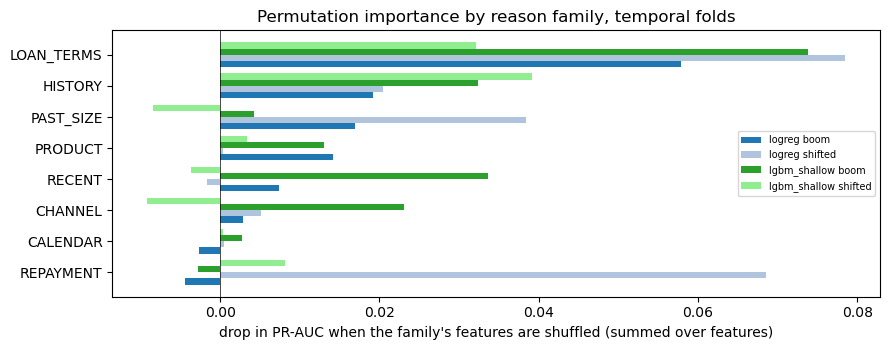

In [5]:
fam_perm = perm.assign(family=perm.feature.map({c: f for f, cs in FAMILIES.items() for c in cs})) \
    .groupby(["model", "regime", "family", "fold"]).pr_auc_drop.sum().groupby(["model", "regime", "family"]).mean().unstack([0, 1])
fig, ax = plt.subplots(figsize=(9, 3.6))
fam_perm = fam_perm.loc[fam_perm[("logreg", "boom")].sort_values().index]
yy = np.arange(len(fam_perm))
for k, (col, c) in enumerate([(("logreg", "boom"), "tab:blue"), (("logreg", "shifted"), "lightsteelblue"),
                              (("lgbm_shallow", "boom"), "tab:green"), (("lgbm_shallow", "shifted"), "lightgreen")]):
    ax.barh(yy + (k - 1.5) * 0.2, fam_perm[col], 0.2, color=c, label=" ".join(col))
ax.set_yticks(yy, fam_perm.index); ax.axvline(0, c="k", lw=.5)
ax.set(xlabel="drop in PR-AUC when the family's features are shuffled (summed over features)", title="Permutation importance by reason family, temporal folds")
ax.legend(fontsize=7); plt.tight_layout(); plt.savefig(FIGURES / "09_family_importance.png", dpi=200); plt.show()

**What drives the model.**
- **Loan terms** (term and amount together) are the strongest family for both models in both regimes; `duration` alone is the single most important feature. Longer loans default more.
- For logistic regression the next drivers are **past loan sizes** and, in the shifted regime, **past repayment problems**, even though only 89 training loans have an earlier default.
- Shallow LightGBM leans more on **borrowing history** (number of earlier loans) and **recent borrowing**, which is part of why its ranking degrades differently over time.
- **Calendar features add nothing out of time** for either model.
- *Contribution size (b) and predictive value (c) are different things.* RECENT and HISTORY move individual scores the most, because borrowers differ a lot on them, while loan terms carry the most predictive value. Calendar features move individual scores noticeably (b) without predicting anything (c), which is noise in the decision.
- Permutation importance spreads credit across correlated features, so family totals are lower bounds.

### (d) Decision: drop calendar features from the deployed model

In [6]:
from src import features as F
nocal = [c for c in M.MAIN_FEATURES if c not in F.CALENDAR]
cmp = {}
for lab, cs in [("with calendar (Section 5)", M.MAIN_FEATURES), ("without calendar (deployed)", nocal)]:
    _, _, fo = V.cross_validate(M.logreg(numeric=cs, class_weight=None), tr, M.inputs(cs), V.temporal(tr))
    cmp[lab] = {**V.summarise(fo), "lift shifted": fo.pr_lift[fo.fold >= 3].mean()}
pd.DataFrame(cmp).T[["pr_auc", "roc_auc", "pr_lift", "lift shifted"]].round(4)

,pr_auc,roc_auc,pr_lift,lift shifted
with calendar (Section 5),0.1428,0.7170,7.0844,1.8144
without calendar (deployed),0.1449,0.7247,7.3724,1.7907


Removing the calendar changes PR-AUC by about +0.002, well inside the ±0.025 noise floor from Section 7. Since calendar features shift individual scores without improving predictions, and "you applied on a Tuesday" could never be given as a reason, the deployed model leaves them out (`M.DEPLOY_FEATURES`). Section 5's numbers remain valid for the model as compared there.

## 9.2 Reason codes for a declined borrower

**Method.** For logistic regression, the log-odds of default decompose exactly into a reference value (the average training applicant) plus one contribution per input, β·(z − z̄). We sum contributions within each family and report the **three families that push hardest towards decline**. `tests/test_reasons.py` checks that the contributions reproduce the model's probability exactly.

**Mapping to plain language** (`src/reasons.py`):

In [7]:
from src.reasons import TEXT
pd.DataFrame({"family": list(TEXT), "inputs": [", ".join(FAMILIES[f]) for f in TEXT], "message to the borrower": list(TEXT.values())})

,family,inputs,message to the borrower
0,LOAN_TERMS,"duration, log_amount, amount_per_day_log, amou...",The amount and repayment period requested ({am...
1,HISTORY,"n_prev_loans, n_prev_resolved, has_resolved_hi...",Your borrowing history with us is short ({n_pr...
2,REPAYMENT,"n_prev_defaults, days_since_last_default, prev...",Our records show an earlier loan that was not ...
3,PAST_SIZE,"prev_amount_mean_log, prev_amount_max_log",The sizes of your previous loans are in a rang...
4,RECENT,"n_active_loans, active_amount_log, days_since_...",Your recent borrowing pattern (time since your...
5,PRODUCT,loan_type,Loans of this product type have had higher rep...
6,CHANNEL,"lender_id, Lender_portion_Funded, n_lenders",Loans funded through this lending channel have...


Rules for the wording: say what the factor is and which way it pointed, use the applicant's own values where that helps, never mention a protected characteristic (none is in the data; proxies are checked in Part D), and never cite the calendar.

### Applying it to new applications

The Kenyan Test loans stand in for new applications. We score them, decline those above the 0.062 threshold, and generate reasons.

In [8]:
ke = te[te.country_id == "Kenya"].copy()
ke["p_default"] = model.predict_proba(ke[cols])[:, 1]
declined = ke[ke.p_default > econ.threshold].copy()
reasons = rc.top_reasons(declined[cols])
declined["reasons"] = reasons
print(f"Kenya Test applications: {len(ke):,}; declined at 0.062: {len(declined):,} ({len(declined) / len(ke):.1%})")
first = pd.Series([r[0]["code"] for r in reasons if r]).value_counts(normalize=True).rename("share of declines (main reason)")
anyr = pd.Series([x["code"] for r in reasons for x in r]).value_counts().div(len(declined)).rename("share of declines (in top 3)")
pd.concat([first, anyr], axis=1).fillna(0).round(3)

Kenya Test applications: 14,983; declined at 0.062: 998 (6.7%)


,share of declines (main reason),share of declines (in top 3)
PRODUCT,0.728,0.754
LOAN_TERMS,0.268,0.507
HISTORY,0.003,0.500
REPAYMENT,0.001,0.010
RECENT,0.000,0.884
PAST_SIZE,0.000,0.305
CHANNEL,0.000,0.040


In [9]:
def letter_lines(row):
    lines = [f"Applicant {row.tbl_loan_id}: P(default) = {row.p_default:.1%} (threshold {econ.threshold:.1%})"]
    lines += [f"  {i + 1}. [{r['code']}] {r['text']}  (log-odds +{r['log_odds']:.2f})" for i, r in enumerate(row.reasons)]
    return "\n".join(lines)

examples = pd.concat([declined.nlargest(1, "p_default"),
                      declined.iloc[(declined.p_default - econ.threshold * 1.5).abs().argsort()[:1]],
                      declined[declined.reasons.map(lambda r: any(x["code"] == "REPAYMENT" for x in r))].head(1)])
for _, row in examples.iterrows():
    print(letter_lines(row)); print()

Applicant 262971: P(default) = 92.7% (threshold 6.2%)
  1. [HISTORY] Your borrowing history with us is short (1 earlier loan(s)).  (log-odds +4.07)
  2. [LOAN_TERMS] The amount and repayment period requested (20,000,000 over 849 days) are typical of loans that were more often not repaid; longer repayment periods carry the most risk in our records.  (log-odds +2.65)
  3. [PRODUCT] Loans of this product type have had higher repayment problems.  (log-odds +1.21)

Applicant 306315: P(default) = 9.3% (threshold 6.2%)
  1. [PRODUCT] Loans of this product type have had higher repayment problems.  (log-odds +1.02)
  2. [LOAN_TERMS] The amount and repayment period requested (22,700 over 14 days) are typical of loans that were more often not repaid; longer repayment periods carry the most risk in our records.  (log-odds +0.83)
  3. [RECENT] Your recent borrowing pattern (time since your last loan and loans currently running) differs from that of borrowers who usually repay.  (log-odds +0.54)

Ap

### A Ghanaian applicant

In [10]:
gh = te[te.country_id == "Ghana"].copy()
gh["p_default"] = model.predict_proba(gh[cols])[:, 1]
print(f"Ghana Test: mean P(default) {gh.p_default.mean():.3f}; share above threshold {(gh.p_default > econ.threshold).mean():.1%}")
g_dec = gh[gh.p_default > econ.threshold]
g_reasons = rc.top_reasons(g_dec[cols])
print(pd.Series([x["code"] for r in g_reasons for x in r]).value_counts().div(len(g_dec)).round(3).to_string())
row = g_dec.assign(reasons=g_reasons).iloc[0]
print(); print(letter_lines(row))

Ghana Test: mean P(default) 0.136; share above threshold 21.7%
RECENT            0.805
LOAN_TERMS        0.666
PRODUCT           0.604
HISTORY           0.480
PRODUCT_UNSEEN    0.396
CHANNEL_UNSEEN    0.040
PAST_SIZE         0.009

Applicant 363003: P(default) = 75.1% (threshold 6.2%)
  1. [LOAN_TERMS] The amount and repayment period requested (110,130 over 180 days) are typical of loans that were more often not repaid; longer repayment periods carry the most risk in our records.  (log-odds +3.59)
  2. [PRODUCT] Loans of this product type have had higher repayment problems.  (log-odds +1.06)
  3. [HISTORY] Your borrowing history with us is short (0 earlier loan(s)).  (log-odds +1.06)


For Ghanaian applicants most product and lender levels are `Unknown`. That one-hot column was never active in training, so its coefficient is zero, but the product family still contributes positively, because the *average* applicant is a Type_1 borrower whose large negative Type_1 coefficient lowers risk. In other words, a Ghana applicant scores as riskier partly because they are **not** on Kenya's dominant, low-risk product, not because their own product has a bad record. Telling them "loans of this product type have had higher repayment problems" would be false. `src/reasons.py` therefore reports `PRODUCT_UNSEEN` ("This product type is new to us, so we have no repayment record for it yet"), which is true and points to the real issue: the model has no evidence about Ghanaian products (Part C).

## 9.3 Limits of these reason codes

1. **Relative, not absolute.** Each reason says a factor pushed the score *above the average applicant's*. It is not a counterfactual ("had you asked for 7 days you would have been approved"); a counterfactual needs a separate search over feasible changes.
2. **Not all reasons are actionable.** PRODUCT and CHANNEL describe the loan the borrower applied for, not the borrower. They are truthful, and BoG's requirement for clear, accurate information (Directive §6) favours stating them, but NkwaPay should pair them with what the borrower *can* change (a shorter term, a smaller amount).
3. **Correlated features.** Families keep related inputs together; term and amount share one family because splitting them attributed the term effect to "size" and produced a message pointing the wrong way. Credit can still move between families (for example loan terms and past loan sizes), so reported log-odds are approximate shares.
4. **Model choice matters.** This exact decomposition exists because the model is linear. For shallow LightGBM, reason codes would need SHAP values, which are approximate and harder to audit; that is one of the reasons Section 7 kept logistic regression when accuracy could not separate the two.